In [ ]:
# 📊 OTT Customer Churn Analysis

## Objective

Analyze customer, subscription, and support data to identify churn patterns,
high-risk customers, major cancellation drivers, and revenue at risk.

### Tools
Python | Pandas | NumPy | Matplotlib | Seaborn | SQLite | Power BI | DAX

### Business Questions

- Who is churning?
- Why are customers leaving?
- Which customer segments have higher churn?
- How much revenue is at risk?
- What actions can improve customer retention?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
import os

In [2]:
print(os.getcwd())

C:\Users\sanak\OneDrive\Documents\Desktop\Churn Analysis


In [3]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.


In [4]:
import sqlite3
import pandas as pd

# Expanded Excel file path
excel_file = 'customer_churn_expanded.xlsx'

# Create SQLite database
conn = sqlite3.connect('customer_churn_expanded.db')

# Read all sheet names
excel_data = pd.ExcelFile(excel_file)

# Convert each Excel sheet into a SQLite table
for sheet in excel_data.sheet_names:

    df = pd.read_excel(
        excel_file,
        sheet_name=sheet
    )

    df.to_sql(
        name=sheet,
        con=conn,
        if_exists='replace',
        index=False
    )

# Close connection
conn.close()

print("All sheets successfully converted into SQLite tables.")

All sheets successfully converted into SQLite tables.


In [5]:
conn = sqlite3.connect('customer_churn_expanded.db')

for table in ['db_customer', 'db_subscription', 'db_support']:
    count = pd.read_sql(
        f"SELECT COUNT(*) AS rows FROM {table}",
        conn
    )['rows'][0]

    print(f"{table}: {count:,} rows")

conn.close()

db_customer: 10,000 rows
db_subscription: 10,000 rows
db_support: 6,494 rows


In [6]:
# 1 import database/ data

In [7]:
# Data Import: db file to pandas, storing each table to a separate df

# Connect to SQLite database
conn = conn = sqlite3.connect('customer_churn_expanded.db')

# sql query to Get all table names
sql_query = """
        SELECT name
        FROM sqlite_master
        WHERE type='table';
"""

# read sql query in pandas
tables = pd.read_sql(sql_query, conn)

# create dataframe for each table
for table_name in tables['name']:
    df = pd.read_sql(f"SELECT * FROM {table_name}", conn) # Read table into dataframe
    globals()[f"df_{table_name}"] = df                    # Create dynamic dataframe name
    print(f"Created dataframe: df_{table_name}")

# Close connection
conn.close()

Created dataframe: df_db_customer
Created dataframe: df_db_subscription
Created dataframe: df_db_support


In [8]:
# Print table names and column names
conn = conn = sqlite3.connect('customer_churn_expanded.db')
for table_name in tables['name']:
    print(f"\nTable Name: {table_name}")
    # Get column information
    columns_query = f"PRAGMA table_info({table_name});"
    columns = pd.read_sql(columns_query, conn)
    print("Columns:")
    print(columns['name'].tolist())

# Close connection
conn.close()


Table Name: db_customer
Columns:
['customerid', 'name', 'country', 'state', 'gender', 'dob', 'interests', 'pincode']

Table Name: db_subscription
Columns:
['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score']

Table Name: db_support
Columns:
['customerid', 'complaint_date', 'escalations', 'csat_score', 'col_1', 'comment']


In [9]:
# 2 data cleaning

In [10]:
df_db_customer.head()  # customer table
df_db_customer.tail()

,customerid,name,country,state,gender,dob,interests,pincode
9995,CH009975,customer_9975,India,Rajasthan,Female,2010-05-08,travel,742507.0
9996,CH009976,customer_9976,India,Maharashtra,Female,1962-07-16,travel,412379.0
9997,CH009977,customer_9977,India,Telangana,Female,1993-07-10,gaming,204936.0
9998,CH009978,customer_9978,India,Punjab,Male,1961-06-24,movies,741936.0
9999,CH009979,customer_9979,India,Maharashtra,Male,2001-12-09,NaN,366209.0


In [11]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   customerid  10000 non-null  str    
 1   name        10000 non-null  str    
 2   country     9997 non-null   str    
 3   state       10000 non-null  str    
 4   gender      10000 non-null  str    
 5   dob         10000 non-null  str    
 6   interests   8504 non-null   str    
 7   pincode     9979 non-null   float64
dtypes: float64(1), str(7)
memory usage: 625.1 KB


In [12]:
# a. rename col - name to customer_name
df_db_customer.rename(columns = {'name' : 'customer_name'}, inplace= True)

In [13]:
# b. drop columns - interest and pincode

# df_db_customer.drop(df_db_customer.columns[-2:], axis=1)
# df_db_customer.drop(df_db_customer.columns[6:], axis=1)

df_db_customer.drop(columns=['interests', 'pincode'], inplace=True)  # using col name

In [14]:
df_db_customer

,customerid,customer_name,country,state,gender,dob
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00
...,...,...,...,...,...,...
9995,CH009975,customer_9975,India,Rajasthan,Female,2010-05-08
9996,CH009976,customer_9976,India,Maharashtra,Female,1962-07-16
9997,CH009977,customer_9977,India,Telangana,Female,1993-07-10
9998,CH009978,customer_9978,India,Punjab,Male,1961-06-24


In [15]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   customerid     10000 non-null  str  
 1   customer_name  10000 non-null  str  
 2   country        9997 non-null   str  
 3   state          10000 non-null  str  
 4   gender         10000 non-null  str  
 5   dob            10000 non-null  str  
dtypes: str(6)
memory usage: 468.9 KB


In [16]:
# c. change data type - dob

df_db_customer['dob'] = pd.to_datetime(
    df_db_customer['dob'],
    format='mixed',
    errors='coerce'
)

In [17]:
df_db_customer[['dob']].head()

,dob
0,1982-04-12
1,1995-11-23
2,1978-02-15
3,2001-08-30
4,1990-05-05


In [18]:
print(df_db_customer['dob'].dtype)
print(df_db_customer['dob'].isna().sum())

datetime64[us]
0


In [19]:
# d. data standardization - gender

# df_db_customer['gender'].unique()
df_db_customer['gender'] = df_db_customer['gender'].replace({'Men' : 'Male', 'Women' : 'Female'})

In [20]:
df_db_customer

,customerid,customer_name,country,state,gender,dob
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05
...,...,...,...,...,...,...
9995,CH009975,customer_9975,India,Rajasthan,Female,2010-05-08
9996,CH009976,customer_9976,India,Maharashtra,Female,1962-07-16
9997,CH009977,customer_9977,India,Telangana,Female,1993-07-10
9998,CH009978,customer_9978,India,Punjab,Male,1961-06-24


In [21]:
df_db_customer['gender'].unique()

<StringArray>
['Male', 'Female']
Length: 2, dtype: str

In [22]:
# e. fix missing values - country

# df_db_customer['country'].isna().sum()
df_db_customer[df_db_customer['country'].isna()]

,customerid,customer_name,country,state,gender,dob
5,0013-MHZWF,durga,NaN,Delhi,Female,1988-12-10
8,0015-UOCOJ,maya,NaN,Kathmandu,Female,1985-07-07
12,0018-NYROU,chitra,NaN,Telangana,Female,2004-12-01


In [23]:
# country and state - unique value pair

# Creating state → country map from non-null rows
state_country_mapping = df_db_customer.dropna(subset=['country']).set_index('state')['country'].to_dict()

# Fill the missing country using State
df_db_customer['country'] = df_db_customer['country'].fillna(df_db_customer['state'].map(state_country_mapping))

In [24]:
df_db_customer[df_db_customer['country'].isna()] # no null value in country col

,customerid,customer_name,country,state,gender,dob


In [25]:
df_db_subscription.head() # subcription table

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaN,NaN,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaN,NaN,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaN,NaN,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [26]:
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               10000 non-null  str    
 1   subscription_start_date  10000 non-null  str    
 2   subscription_type        10000 non-null  str    
 3   renewal_date             10000 non-null  str    
 4   plan_type                10000 non-null  str    
 5   contract_type            10000 non-null  str    
 6   cancellation_date        2807 non-null   str    
 7   cancellation_reason      2807 non-null   str    
 8   monthly_charges          10000 non-null  float64
 9   cltv                     10000 non-null  int64  
 10  churn_score              10000 non-null  int64  
dtypes: float64(1), int64(2), str(8)
memory usage: 859.5 KB


In [27]:
date_col = ['subscription_start_date', 'renewal_date', 'cancellation_date']

df_db_subscription[date_col] = df_db_subscription[date_col].apply(pd.to_datetime)
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               10000 non-null  str           
 1   subscription_start_date  10000 non-null  datetime64[us]
 2   subscription_type        10000 non-null  str           
 3   renewal_date             10000 non-null  datetime64[us]
 4   plan_type                10000 non-null  str           
 5   contract_type            10000 non-null  str           
 6   cancellation_date        2807 non-null   datetime64[us]
 7   cancellation_reason      2807 non-null   str           
 8   monthly_charges          10000 non-null  float64       
 9   cltv                     10000 non-null  int64         
 10  churn_score              10000 non-null  int64         
dtypes: datetime64[us](3), float64(1), int64(2), str(5)
memory usage: 859.5 KB


In [28]:
df_db_support.head() # support table

,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28 00:00:00,N,60,None,service issue
1,0003-MKNFE,2024-08-28 00:00:00,Y,10,None,demaned refund
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20,None,NaN
3,0013-MHZWF,2025-03-18 00:00:00,N,90,None,guidance to renew
4,0013-SMEOE,2024-11-01 00:00:00,N,30,None,NaN


In [29]:
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 6494 entries, 0 to 6493
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customerid      6494 non-null   str   
 1   complaint_date  6494 non-null   str   
 2   escalations     6494 non-null   str   
 3   csat_score      6494 non-null   int64 
 4   col_1           0 non-null      object
 5   comment         6489 non-null   str   
dtypes: int64(1), object(1), str(4)
memory usage: 304.5+ KB


In [30]:
# drop columns
df_db_support.drop(columns=['col_1', 'comment'], inplace=True)

In [31]:
# change data type to date - complaint_date

df_db_support['complaint_date'] = pd.to_datetime(
    df_db_support['complaint_date'],
    format='mixed',
    errors='coerce'
)

df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 6494 entries, 0 to 6493
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      6494 non-null   str           
 1   complaint_date  6494 non-null   datetime64[us]
 2   escalations     6494 non-null   str           
 3   csat_score      6494 non-null   int64         
dtypes: datetime64[us](1), int64(1), str(2)
memory usage: 203.1 KB


In [32]:
# 3 feature engineering and data analysis

In [33]:
# create a new col using existing col - churn flag

# Customer is churned if cancellation_date is not null
df_db_subscription['churn_flag'] = np.where(df_db_subscription['cancellation_date'].notna(), 1, 0)
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34,0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,8,0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1


In [34]:
# merge dataframe -  joins

In [35]:
df_db_subscription.shape

(10000, 12)

In [36]:
# first fix support table duplicates then merge
# Note: while merging df's always check the shape before and after
df = (df_db_subscription
            .merge(df_db_customer, on = 'customerid', how= 'left')
            .merge(df_db_support, on = 'customerid', how= 'left') )

In [37]:
df_db_subscription.shape

(10000, 12)

In [38]:
df.shape

(11760, 20)

In [39]:
print('df_db_subscription unique value:', df_db_subscription['customerid'].nunique())
print('df_db_customer unique value:', df_db_customer['customerid'].nunique())
print('df_db_support unique value:', df_db_support['customerid'].nunique())
print('df_db_support all value:', df_db_support['customerid'].size)

df_db_subscription unique value: 10000
df_db_customer unique value: 10000
df_db_support unique value: 4734
df_db_support all value: 6494


In [40]:
df_db_support

,customerid,complaint_date,escalations,csat_score
0,0003-MKNFE,2024-08-28,N,60
1,0003-MKNFE,2024-08-28,Y,10
2,0013-EXCHZ,2024-01-20,Y,20
3,0013-MHZWF,2025-03-18,N,90
4,0013-SMEOE,2024-11-01,N,30
...,...,...,...,...
6489,CH009968,2025-09-03,N,61
6490,CH009973,2024-07-09,Y,33
6491,CH009974,2025-06-27,Y,36
6492,CH009974,2025-09-17,N,36


In [41]:
df_db_support['complaint_count'] = df_db_support.groupby('customerid')['customerid'].transform('count')

In [42]:
df_db_support = df_db_support.sort_values('complaint_date').drop_duplicates('customerid', keep= 'last')

In [43]:
df_db_support['customerid'].size

4734

In [44]:
df_db_support

,customerid,complaint_date,escalations,csat_score,complaint_count
1068,CH001653,2024-01-01,N,67,1
3525,CH005506,2024-01-01,Y,29,1
2751,CH004263,2024-01-01,N,47,1
4427,CH006859,2024-01-01,N,62,1
4559,CH007068,2024-01-02,N,82,1
...,...,...,...,...,...
718,CH001112,2025-10-01,N,68,2
1866,CH002873,2025-10-01,N,58,2
4267,CH006597,2025-10-01,N,87,1
474,CH000719,2025-10-01,N,55,3


In [45]:
# merge df
df = (df_db_subscription
            .merge(df_db_customer, on = 'customerid', how= 'left')
            .merge(df_db_support, on = 'customerid', how= 'left') )

In [46]:
df.shape

(10000, 21)

In [47]:
# export dataframe to csv file
df.to_csv('exported_churn_data.csv', index=False)

In [48]:
# Data analysis

In [49]:
# 1. Churn Rate

In [50]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count'],
      dtype='str')

In [51]:
# 1. churn Rate
churn_rate = df['churn_flag'].mean()*100
print("Churn Rate = ", round(churn_rate,2), "%")

Churn Rate =  28.07 %


In [52]:
# 2. Retenion Rate
retention_rate = 100 - churn_rate
print("Retention Rate = ", round(retention_rate,2), "%")

Retention Rate =  71.93 %


In [53]:
# 3. Churn by Plan type
churn_by_plan = (df.groupby('plan_type')['churn_flag'].mean().mul(100).round(2).reset_index(name='churn_rate_pct'))
print(churn_by_plan)

  plan_type  churn_rate_pct
0     Basic           30.80
1   Premium           23.05
2  Standard           27.46


In [54]:
# 4 a. Churn by state + sum(revenue) & count of users

churn_by_state = (
    df.groupby('state')
      .agg(
          churn_rate=('churn_flag', 'mean'),
          total_revenue=('monthly_charges', 'sum'),
          user_count=('customerid', 'count')
      )
      .reset_index()
)

churn_by_state['churn_rate'] = churn_by_state['churn_rate'] * 100

print(churn_by_state.round(2))


             state  churn_rate  total_revenue  user_count
0            Bihar       26.57        6170.96         478
1            Delhi       29.34       10585.59         801
2          Gujarat       28.88        9004.04         703
3          Haryana       30.78        6412.54         497
4        Jharkhand       27.63        3900.51         304
5        Karnataka       27.56       13249.07        1016
6        Kathmandu        0.00          20.98           2
7           Kerala       27.49        7597.50         582
8   Madhya Pradesh       27.15        4837.72         383
9      Maharashtra       25.94       13278.49        1037
10       Meghalaya       66.67          42.97           3
11        Nagaland        0.00          22.99           1
12          Punjab       27.44        6281.80         492
13       Rajasthan       26.71        8054.36         614
14      Tamil Nadu       27.23       10048.39         775
15       Telangana       31.15        9274.44         719
16   Uttar Pra

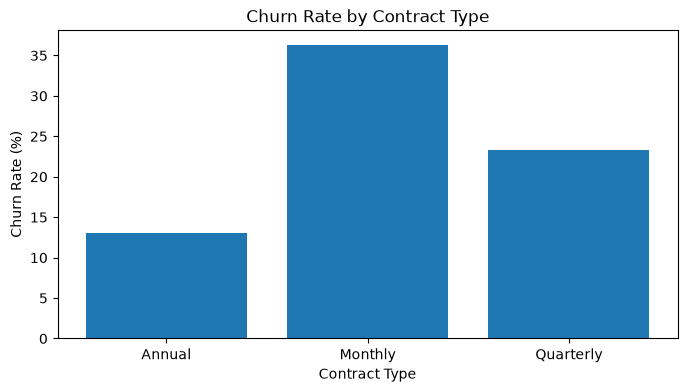

In [57]:
# 4.4 Churn by Contract Type

churn_by_contract = df_visual.groupby('contract_type')['churn_flag'].mean() * 100

plt.figure(figsize=(8,4))
plt.bar(churn_by_contract.index, churn_by_contract.values)

plt.title('Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')

plt.show()

In [58]:
# 4 b. Churn by subscription type + sum(revenue) & count of users

churn_by_subscription = (
    df.groupby('subscription_type')
      .agg(
          churn_rate=('churn_flag', 'mean'),
          total_revenue=('monthly_charges', 'sum'),
          user_count=('customerid', 'count')
      )
      .reset_index()
)

churn_by_subscription['churn_rate'] = churn_by_subscription['churn_rate'] * 100

print(churn_by_subscription.round(2))

  subscription_type  churn_rate  total_revenue  user_count
0           Organic       29.08       54970.20        4243
1              Paid       27.53       38827.89        2990
2          Referral       27.06       25794.16        1977
3          Refferal       27.22       10023.13         790


In [59]:
# 5. ARPU - Avg Revenue per user
arpu = df['monthly_charges'].mean()
print('ARPU = ', round(arpu,2))

ARPU =  12.96


In [60]:
# Calculate customer age

today = pd.Timestamp.today()

df['age'] = (
    (today - pd.to_datetime(df['dob'])).dt.days / 365.25
).round(0)

print(df[['dob', 'age']].head())

         dob   age
0 1982-04-12  44.0
1 1995-11-23  31.0
2 1978-02-15  49.0
3 2001-08-30  25.0
4 1990-05-05  36.0


In [61]:
# 6. Avg Customer Tenure
# count of days users has used our service : cancellation date else current date
today = pd.Timestamp.today()

df['tenure_days'] = np.where(
        df['cancellation_date'].notna(),

    (df['cancellation_date'] - df['subscription_start_date']).dt.days,

    (today - df['subscription_start_date']).dt.days
)

avg_tenure = df['tenure_days'].mean()
print("Avg Tenure (Days) = ", round(avg_tenure),0)

Avg Tenure (Days) =  935 0


In [62]:
# 7. Revenue at risk - revenue lost from churned users
revenue_at_risk = df.loc[df['churn_flag']==1, 'monthly_charges'].sum()
print("Revenue at Risk (Rs 'K') =", revenue_at_risk)

Revenue at Risk (Rs 'K') = 35051.64


In [63]:
# 7b. Revenue at Risk - High Risk Customers

revenue_at_risk_high = df.loc[
    df['churn_score'] > 70,
    'monthly_charges'
].sum()

print(
    "Revenue at Risk (High Risk Customers) =",
    round(revenue_at_risk_high, 2)
)

Revenue at Risk (High Risk Customers) = 15352.33


In [64]:
# 7b. Revenue at Risk - High Risk Customers

revenue_at_risk_high = df.loc[
    df['churn_score'] > 70,
    'monthly_charges'
].sum()

print("Revenue at Risk (High Risk Customers) =", round(revenue_at_risk_high, 2))

Revenue at Risk (High Risk Customers) = 15352.33


In [65]:
# 8. Esclation Rate
escalation_rate = (df['escalations']=='Y').mean()*100
print("Esclation Rate = ", round(escalation_rate, 2), "%")

Esclation Rate =  7.69 %


In [66]:
# 9. Avg Complaint Per User
avg_complaints = df['complaint_count'].sum() / df['customerid'].nunique()
print("Avg Compliants Per User = ", round(avg_complaints, 2))

Avg Compliants Per User =  0.65


In [67]:
# 10. Correlation Esclation vs Churn
df['escalations'] = np.where(df['escalations'] == 'Y', 1, 0) # encoding string to int type
corr_df = df[['escalations', 'churn_flag']].dropna()

correlation = corr_df['escalations'].corr(df['churn_flag'])
print("Correlation between esclation vs churn is = ", round(correlation,2))

Correlation between esclation vs churn is =  0.11


In [68]:
# 11. Create a column using existing col - Churn risk
conditions = [
        (df['churn_score'] < 50),
        (df['churn_score'] >= 50) & (df['churn_score'] < 70),
        (df['churn_score'] >= 70)
]

choices = ['low', 'med', 'high']

df['churn_risk'] = np.select(conditions, choices, default='unkown')

In [ ]:
# Visualization using Matplotlib

In [69]:
# best practice to create a copy then work on it
df_visual = df.copy()

In [70]:
# 12. Churn by Cancellation Reason

churn_reason = (
    df_visual[df_visual['churn_flag'] == 1]
    ['cancellation_reason']
    .value_counts()
)

print(churn_reason)

cancellation_reason
Switched to competitor    986
Price too high            703
Poor content              627
Service issue             487
Too expensive               1
Not enough content          1
Poor streaming quality      1
Forgot to cancel trial      1
Name: count, dtype: int64


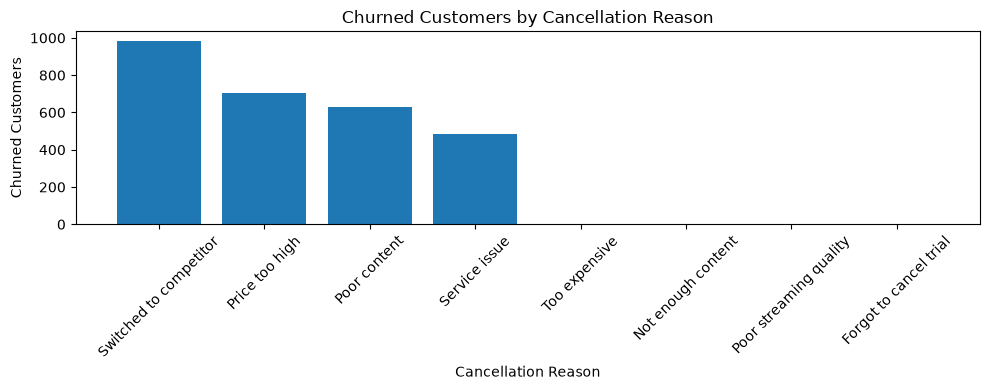

In [71]:
plt.figure(figsize=(10,4))

plt.bar(churn_reason.index, churn_reason.values)

plt.title('Churned Customers by Cancellation Reason')
plt.xlabel('Cancellation Reason')
plt.ylabel('Churned Customers')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [72]:
# 13. Escalation vs Churn

escalation_churn = (
    df_visual.groupby('escalations')['churn_flag']
    .mean() * 100
)

print(escalation_churn)

escalations
0    26.616835
1    45.513654
Name: churn_flag, dtype: float64


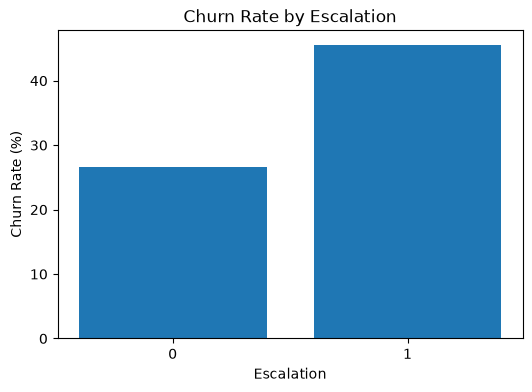

In [73]:
plt.figure(figsize=(6,4))

plt.bar(escalation_churn.index.astype(str), escalation_churn.values)

plt.title('Churn Rate by Escalation')
plt.xlabel('Escalation')
plt.ylabel('Churn Rate (%)')

plt.show()

In [74]:
# 14. Final KPI Summary

kpi_summary = {
    'Churn Rate (%)': round(df['churn_flag'].mean() * 100, 2),
    'Retention Rate (%)': round((1 - df['churn_flag'].mean()) * 100, 2),
    'ARPU': round(df['monthly_charges'].sum() / df['customerid'].nunique(), 2),
    'Avg Tenure (Days)': round(df_visual['tenure_days'].mean(), 2),
    'Revenue at Risk': round(revenue_at_risk, 2),
    'High Risk Revenue at Risk': round(revenue_at_risk_high, 2),
    'Escalation Rate (%)': round(escalation_rate, 2),
    'Avg Complaints per User': round(avg_complaints, 2),
    'Escalation vs Churn Correlation': round(correlation, 2)
}

for k, v in kpi_summary.items():
    print(f"{k}: {v}")

Churn Rate (%): 28.07
Retention Rate (%): 71.93
ARPU: 12.96
Avg Tenure (Days): 934.7
Revenue at Risk: 35051.64
High Risk Revenue at Risk: 15352.33
Escalation Rate (%): 7.69
Avg Complaints per User: 0.65
Escalation vs Churn Correlation: 0.11


In [75]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count', 'age',
       'tenure_days', 'churn_risk'],
      dtype='str')

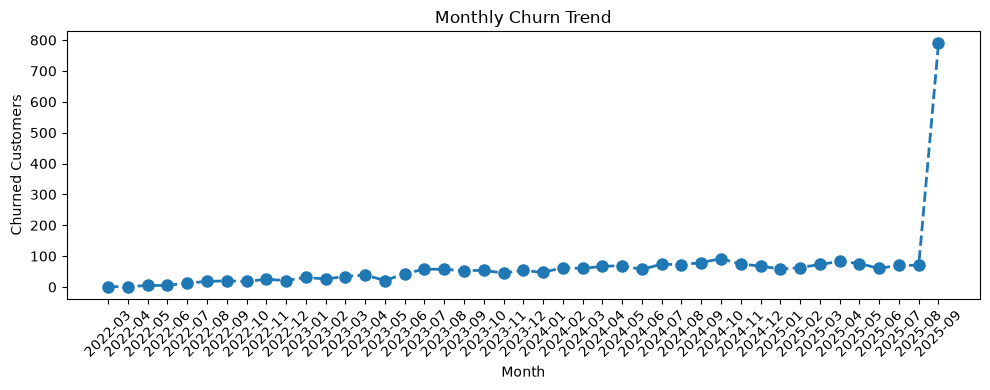

In [76]:
# 4.1 Monthly Churn Trend (Time Series KPI)

df_visual['cancellation_month'] = df_visual['cancellation_date'].dt.to_period('M')

churn_trend = df_visual[df_visual['churn_flag'] == 1].groupby('cancellation_month').size()

plt.figure(figsize=(10, 4))
plt.plot(churn_trend.index.astype(str), churn_trend.values,
         marker='o', linestyle='--', linewidth=2, markersize=8)

plt.title('Monthly Churn Trend')
plt.xlabel('Month')
plt.ylabel('Churned Customers')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

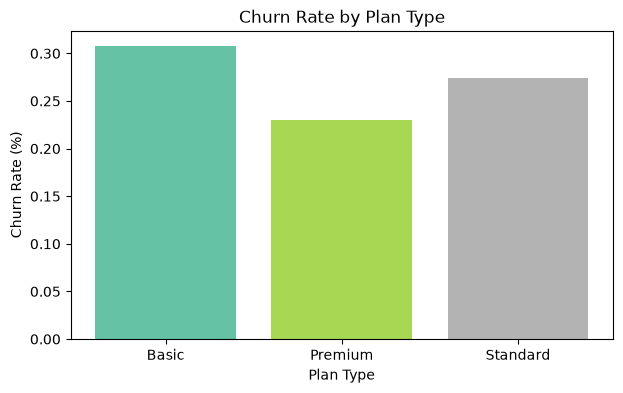

In [77]:
# 4.2 Churn Rate by Plan type
churn_plan = df_visual.groupby('plan_type')['churn_flag'].mean()

# colors = ['yellow', 'purple', 'blue']
colors = plt.cm.Set2(np.linspace(0, 1, len(churn_plan)))

plt.figure(figsize=(7,4))
plt.bar(churn_plan.index, churn_plan.values, color = colors)

plt.title('Churn Rate by Plan Type')
plt.xlabel('Plan Type')
plt.ylabel('Churn Rate (%)')
plt.show()

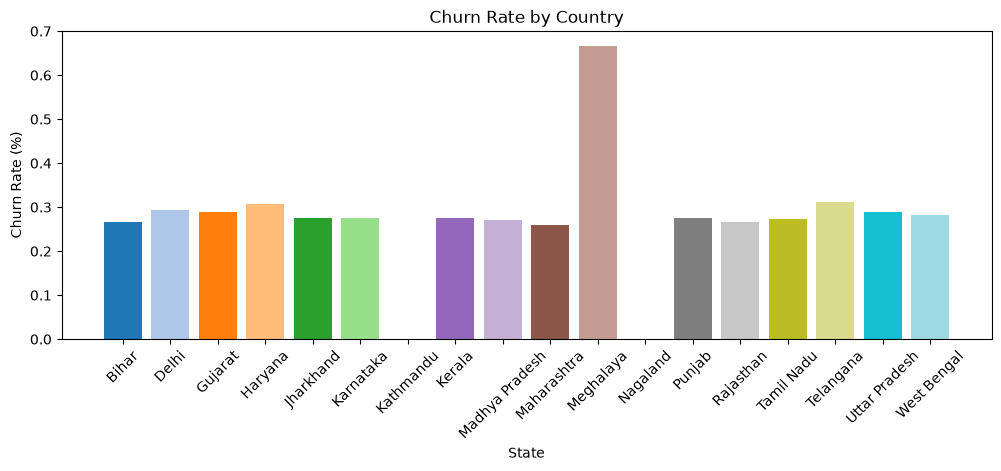

In [78]:
# 4.3 Churn by States
churn_plan = df_visual.groupby('state')['churn_flag'].mean()

# colors = ['yellow', 'purple', 'blue']
colors = plt.cm.tab20(np.linspace(0, 1, len(churn_plan)))

plt.figure(figsize=(12,4))
plt.bar(churn_plan.index, churn_plan.values, color = colors)

plt.title('Churn Rate by Country')
plt.xlabel('State')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=45)
plt.show()

In [79]:
churn_plan.loc[['Kathmandu', 'Nagaland']]

state
Kathmandu    0.0
Nagaland     0.0
Name: churn_flag, dtype: float64

In [80]:
# Visualization using seaborn

In [81]:
# encoding - convert str to numeric so that we can find corr between features
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count', 'age',
       'tenure_days', 'churn_risk', 'cancellation_month'],
      dtype='str')

In [82]:
df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']].head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Annual,12,0,low,0
1,Premium,Annual,91,1,high,1
2,Basic,Monthly,34,0,low,0
3,Premium,Annual,8,0,low,0
4,Standard,Monthly,88,1,high,1


In [83]:
# remove warnings
import warnings
warnings.filterwarnings("ignore")

In [84]:
# incorrect method of encoding - as numbers are not assigned based on priority
df_encoded = df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']]

categorial_cols = ['plan_type', 'contract_type', 'churn_risk']

for col in categorial_cols:
    df_encoded[col] = df_encoded[col].astype('category').cat.codes

<Axes: >

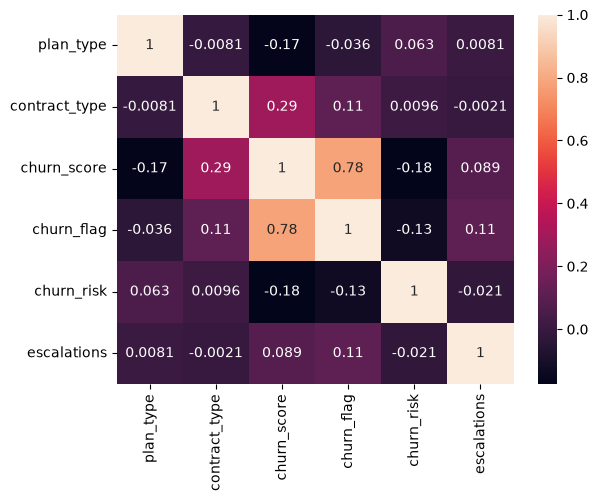

In [85]:
# Heatmap (correlation matrix)

sns.heatmap(df_encoded.corr(), annot=True)

In [86]:
print('plan_type :', df_visual['plan_type'].unique())
print('contract_type :', df_visual['contract_type'].unique())
print('churn_risk :', df_visual['churn_risk'].unique())

plan_type : <StringArray>
['Standard', 'Premium', 'Basic']
Length: 3, dtype: str
contract_type : <StringArray>
['Annual', 'Monthly', 'Quarterly']
Length: 3, dtype: str
churn_risk : <StringArray>
['low', 'high', 'med']
Length: 3, dtype: str


In [87]:
# Correct method of encoding - based on priority
df_encoded = df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']]

order_mappings = {
    'plan_type' : ['Basic', 'Standard', 'Premium'],
    'contract_type' : ['Monthly', 'Annual'],
    'churn_risk': ['low', 'med', 'high']
    }

for col, order in order_mappings.items():
    df_encoded[col] = pd.Categorical(df_encoded[col].astype('category'), categories=order, ordered=True).codes

In [88]:
df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']].head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Annual,12,0,low,0
1,Premium,Annual,91,1,high,1
2,Basic,Monthly,34,0,low,0
3,Premium,Annual,8,0,low,0
4,Standard,Monthly,88,1,high,1


In [89]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,1,1,12,0,0,0
1,2,1,91,1,2,1
2,0,0,34,0,0,0
3,2,1,8,0,0,0
4,1,0,88,1,2,1


<Axes: >

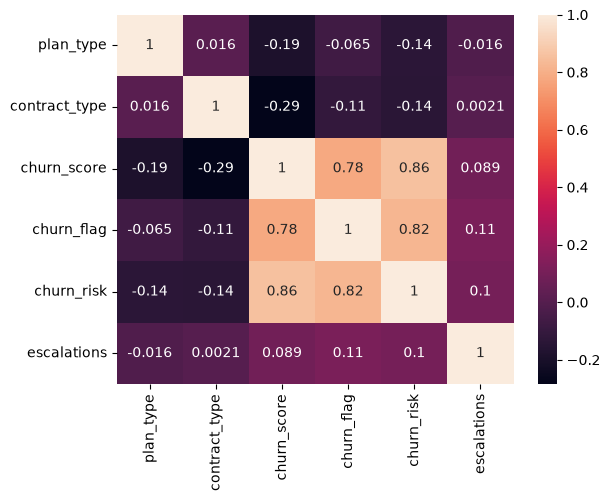

In [90]:
# Heatmap (correlation matrix)
sns.heatmap(df_encoded.corr(), annot=True)

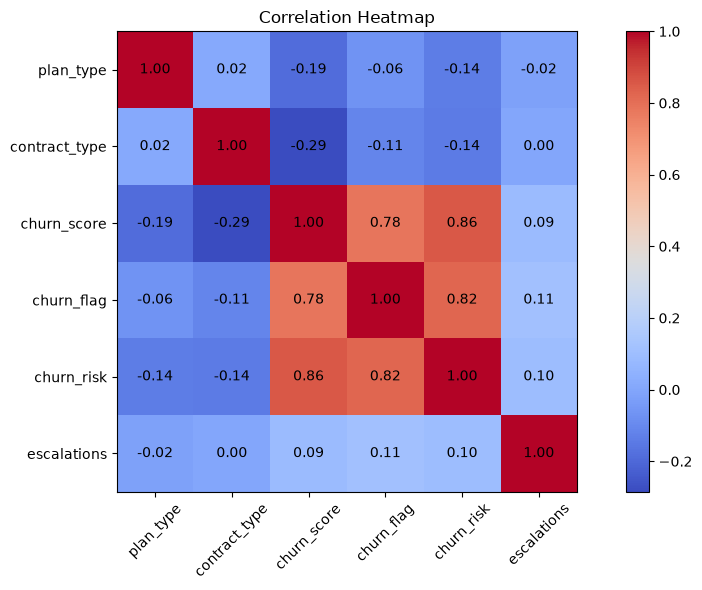

In [91]:
# Heatmap Using Matplotlib - difficult to plot it

corr_matrix = df_encoded.corr() # Correlation matrix

fig, ax = plt.subplots(figsize=(10, 6)) # Create figure

cax = ax.imshow(corr_matrix, cmap='coolwarm') # Heatmap

fig.colorbar(cax) # Add colorbar

# Axis labels
ax.set_xticks(np.arange(len(corr_matrix.columns)))
ax.set_yticks(np.arange(len(corr_matrix.columns)))

ax.set_xticklabels(corr_matrix.columns, rotation=45)
ax.set_yticklabels(corr_matrix.columns)

# Annotate values inside cells
for i in range(len(corr_matrix.columns)):
    for j in range(len(corr_matrix.columns)):
        ax.text(
            j,
            i,
            f"{corr_matrix.iloc[i, j]:.2f}",
            ha='center',
            va='center'
        )

plt.title('Correlation Heatmap') # Title

plt.tight_layout()
plt.show()

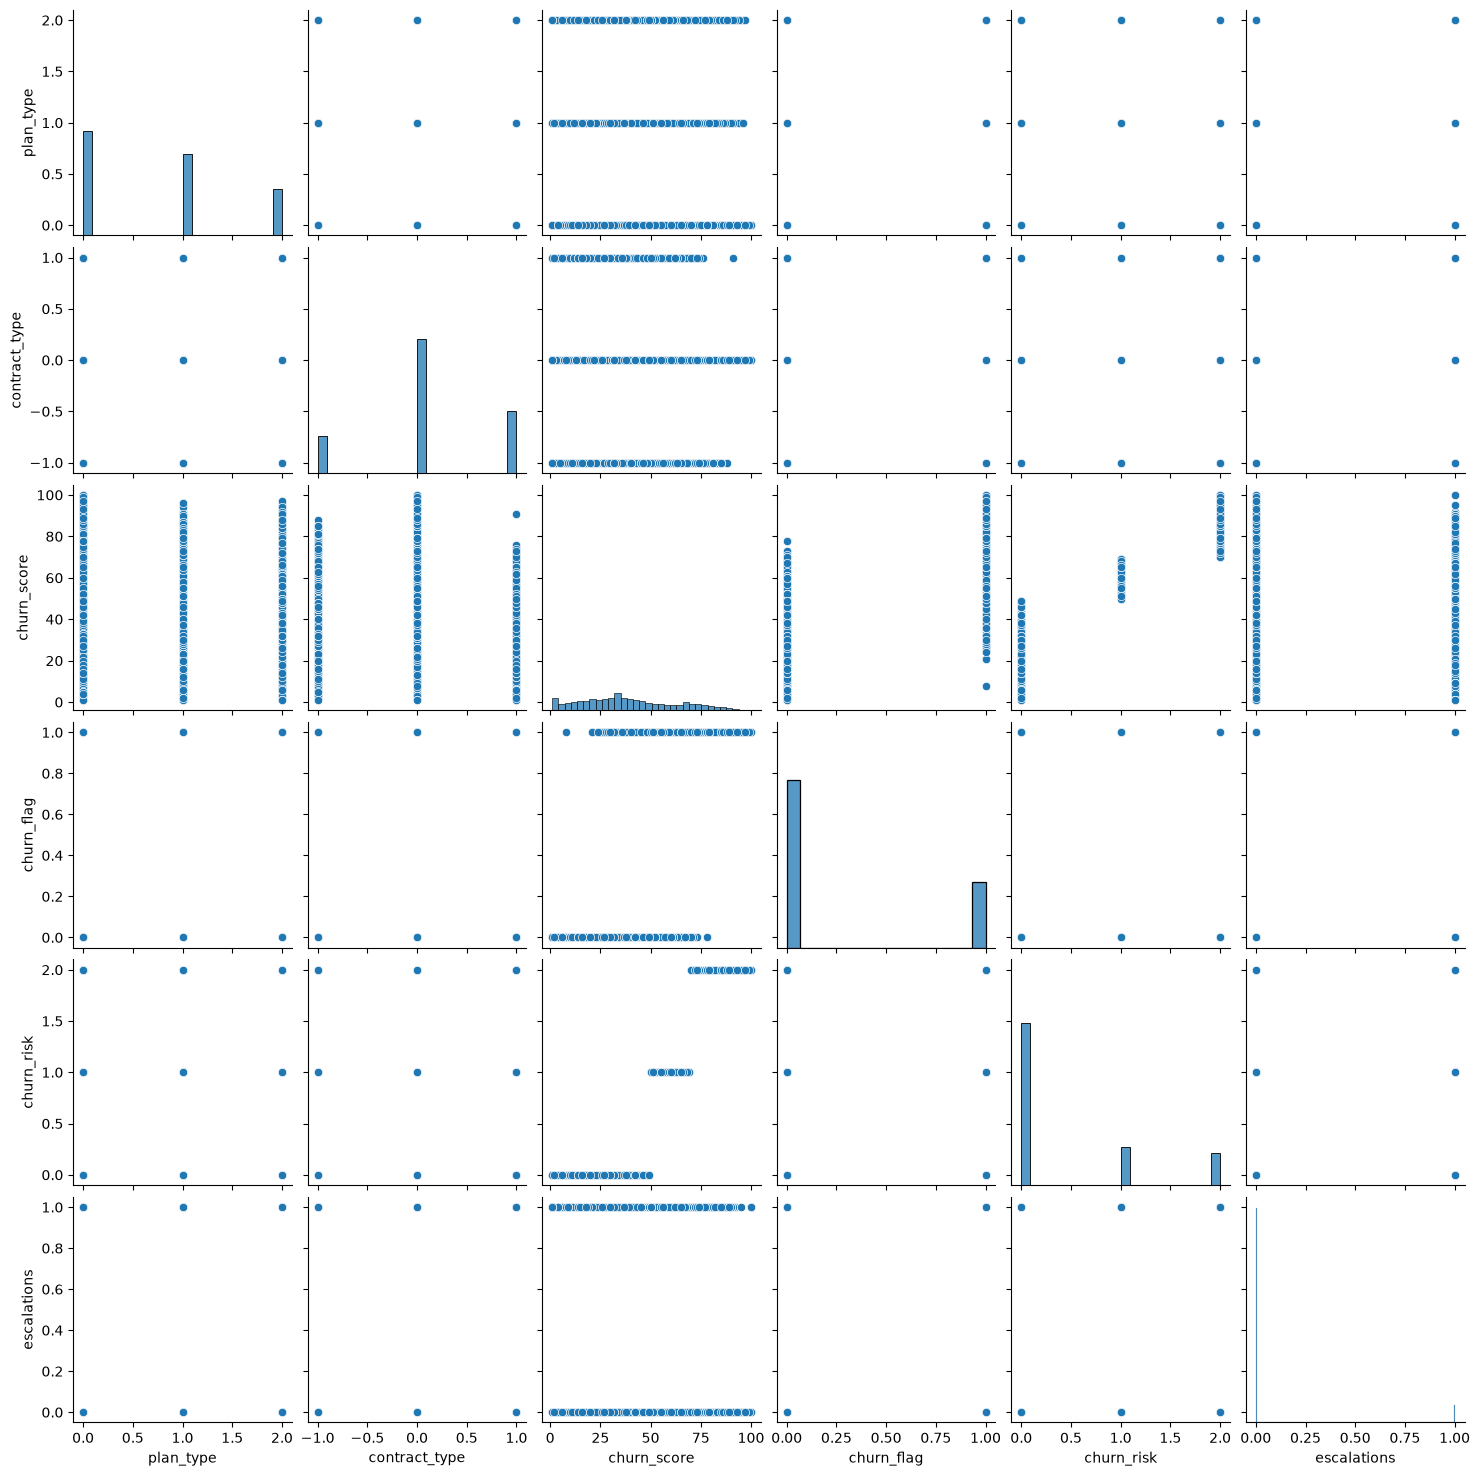

In [93]:
# pairplot - Plot pairwise relationships in a dataset
sns.pairplot(df_encoded)

In [94]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count', 'age',
       'tenure_days', 'churn_risk', 'cancellation_month'],
      dtype='str')

In [95]:
df_visual['monthly_charges'] = df_visual['monthly_charges'].clip(upper=25)

In [96]:
df_visual['monthly_charges'].describe()

count    10000.000000
mean        12.954739
std          4.418325
min          5.000000
25%          9.180000
50%         12.510000
75%         15.600000
max         25.000000
Name: monthly_charges, dtype: float64

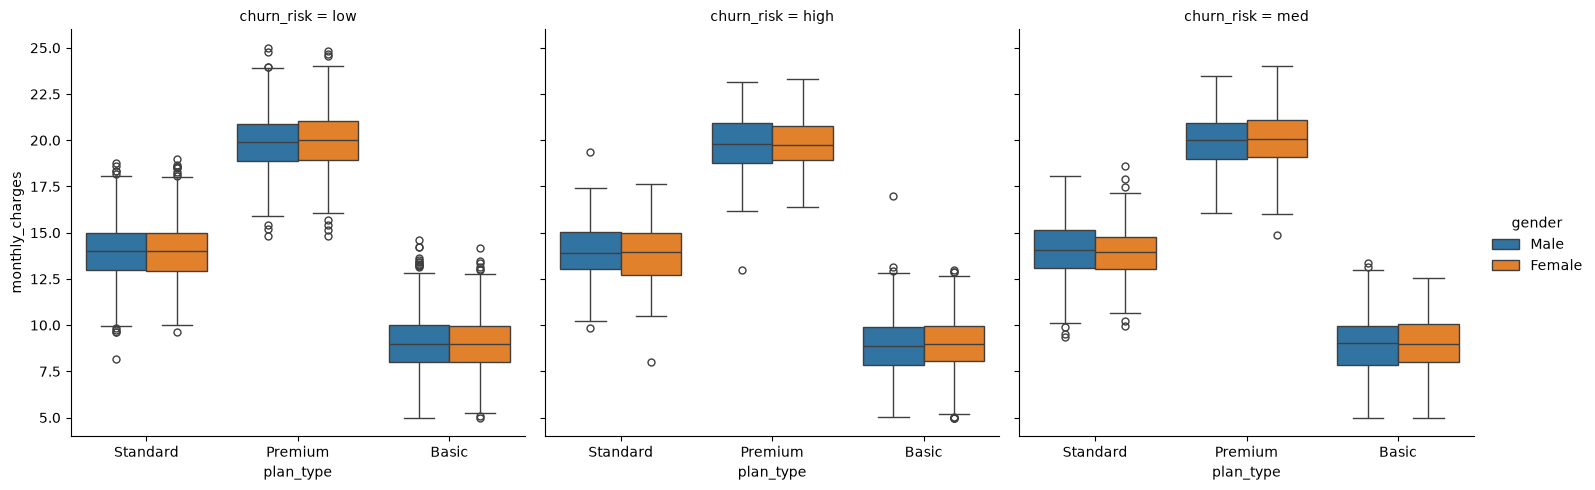

In [97]:
# catplt/Facegrid plot - multi-dim comparison

sns.catplot(
    data=df_visual,
    x='plan_type',
    y='monthly_charges',
    hue='gender',
    col='churn_risk',
    kind='box'
)

In [98]:
# Pivot Table

In [99]:
# Pivot Table

pivot = pd.pivot_table(
    df_visual,
    index='plan_type',
    values='churn_flag',
    aggfunc='mean'
)

pivot['churn_flag'] = pivot['churn_flag'] * 100

pivot

,churn_flag
plan_type,
Basic,30.803571
Premium,23.054041
Standard,27.462175


In [100]:
# pivot table using multiple cols and agg type

pivot = pd.pivot_table(
    df_visual,
    index='plan_type',
    values=['monthly_charges', 'customerid', 'churn_flag'],
    aggfunc={
        'monthly_charges': 'sum',
        'customerid': 'nunique',
        'churn_flag': 'mean'
    }
)

pivot = pivot.rename(columns={
    'monthly_charges': 'Total Monthly Charges',
    'customerid': 'Customers',
    'churn_flag': 'Churn Rate'
})

pivot['Churn Rate'] = pivot['Churn Rate'].round(2)
pivot

,Churn Rate,Customers,Total Monthly Charges
plan_type,,,
Basic,0.31,4480,40304.70
Premium,0.23,2017,40220.65
Standard,0.27,3503,49022.04
